# iPSC-EC CRT QQ point export for d0–d3

This notebook wrapper runs `iPSC_EC_QQ_export_all_days.py`. It exports per-day observed-target and non-targeting pseudo-target p-values plus QQ coordinates for replotting. The paths and parameter defaults are taken from `qq_sweep_test.ipynb` and `ipsc_ec_qq.ipynb`.

In [1]:
from pathlib import Path

PROGRAMDE_ROOT = '/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE'
DATA_DIR = '/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data'
CNMF_DIR = '/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all'
GUIDE_LONG_TEMPLATE = '/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/{day}_sceptre_transfer/{day}_grna_assignments_long.csv'
OUT_DIR = 'results/ipsc_ec_qq_exports'

DAYS = ['d0', 'd1', 'd2', 'd3']
K = 50
DENSITY_THRESHOLD = '0_2'
B = 10000
N_JOBS = 4

print('Output root:', Path(OUT_DIR) / f'k_{K}.dt_{DENSITY_THRESHOLD}')

Output root: results/ipsc_ec_qq_exports/k_50.dt_0_2


## Optional path check

This cell does not run CRT. It prints the H5MU, guide, and cNMF usage candidates that the script will use.

In [2]:
!python iPSC_EC_QQ_export_all_days.py \
  --programde-root "{PROGRAMDE_ROOT}" \
  --data-dir "{DATA_DIR}" \
  --cnmf-dir "{CNMF_DIR}" \
  --guide-long-csv-template "{GUIDE_LONG_TEMPLATE}" \
  --out-dir "{OUT_DIR}" \
  --days {' '.join(DAYS)} \
  --k {K} \
  --density-threshold "{DENSITY_THRESHOLD}" \
  --B {B} \
  --n-jobs {N_JOBS} \
  --ntc-label SAFE \
  --ntc-label non-targeting \
  --ntc-label NTC \
  --dry-run

iPSC-EC QQ export
days: ['d0', 'd1', 'd2', 'd3']
model: k_50.dt_0_2
data_dir: /oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data
cnmf_dir: /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all
out_dir: results/ipsc_ec_qq_exports/k_50.dt_0_2
B: 10000 n_jobs: 4

Combined outputs:
  manifest: results/ipsc_ec_qq_exports/k_50.dt_0_2/QQ_export_manifest.csv


## Run export

This performs the CRT runs and writes per-day CSVs. For a quicker smoke test, set `B = 1023` before running this cell.

In [3]:
!python iPSC_EC_QQ_export_all_days.py \
  --programde-root "{PROGRAMDE_ROOT}" \
  --data-dir "{DATA_DIR}" \
  --cnmf-dir "{CNMF_DIR}" \
  --guide-long-csv-template "{GUIDE_LONG_TEMPLATE}" \
  --out-dir "{OUT_DIR}" \
  --days {' '.join(DAYS)} \
  --k {K} \
  --density-threshold "{DENSITY_THRESHOLD}" \
  --B {B} \
  --n-jobs {N_JOBS} \
  --ntc-label SAFE \
  --ntc-label non-targeting \
  --ntc-label NTC \
  --skip-if-exists

iPSC-EC QQ export
days: ['d0', 'd1', 'd2', 'd3']
model: k_50.dt_0_2
data_dir: /oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/2.normalized_data/normalized_data
cnmf_dir: /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7/012726_100k_cells_20iter_allHVG_torch_halsvar_batch_e7_all
out_dir: results/ipsc_ec_qq_exports/k_50.dt_0_2
B: 10000 n_jobs: 4
/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/muon/_core/preproc.py:31: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if Version(scanpy.__version__) < Version("1.10"):

=== d0: K=50, dt=0_2 ===
/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1598: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) t

## Read exported points

In [4]:
import pandas as pd

model_root = Path(OUT_DIR) / f'k_{K}.dt_{DENSITY_THRESHOLD}'
points_path = model_root / 'all_days_QQ_points.csv'
manifest_path = model_root / 'QQ_export_manifest.csv'

manifest = pd.read_csv(manifest_path)
display(manifest)

points = pd.read_csv(points_path)
display(points.head())
points.groupby(['day', 'pvalue_type', 'series_type']).size().to_frame('n_points')

,day,status,output_dir,h5mu_path,usage_path,guide_long_csv,n_cells,n_programs,n_guides,matched_usage_cells,n_observed_target_empirical_points,n_ntc_pseudotarget_empirical_points,n_observed_target_skew_points,n_ntc_pseudotarget_skew_points,message,qq_points_csv,qq_points_rows
0,d0,completed,results/ipsc_ec_qq_exports/k_50.dt_0_2/d0,/oak/stanford/groups/engreitz/Users/opushkar/c...,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,38609,50,1926,38609,14900,6100,14900,6100,NaN,results/ipsc_ec_qq_exports/k_50.dt_0_2/d0/d0_Q...,42200
1,d1,completed,results/ipsc_ec_qq_exports/k_50.dt_0_2/d1,/oak/stanford/groups/engreitz/Users/opushkar/c...,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,16925,50,1926,16925,14900,4650,14900,4650,NaN,results/ipsc_ec_qq_exports/k_50.dt_0_2/d1/d1_Q...,39300
2,d2,completed,results/ipsc_ec_qq_exports/k_50.dt_0_2/d2,/oak/stanford/groups/engreitz/Users/opushkar/c...,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,21980,50,1926,21980,14900,6350,14900,6350,NaN,results/ipsc_ec_qq_exports/k_50.dt_0_2/d2/d2_Q...,42700
3,d3,completed,results/ipsc_ec_qq_exports/k_50.dt_0_2/d3,/oak/stanford/groups/engreitz/Users/opushkar/c...,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,44102,50,1926,44102,14900,7750,14900,7750,NaN,results/ipsc_ec_qq_exports/k_50.dt_0_2/d3/d3_Q...,45500


/tmp/ipykernel_64318/3847999645.py:10: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  points = pd.read_csv(points_path)


,source_csv,day,pvalue_type,series,series_type,source,target_name,program_name,pvalue,rank,n_points,expected_pvalue,expected_neglog10_p,observed_neglog10_p,ensemble,group_id
0,d0/d0_QQ_points.csv,d0,empirical,Observed target p-values,observed_target,observed target rows from pvals_raw_df,PAXBP1,1,0.0001,1,14900,0.000034,4.474216,4.000043,NaN,NaN
1,d0/d0_QQ_points.csv,d0,empirical,Observed target p-values,observed_target,observed target rows from pvals_raw_df,STAG2,1,0.0001,2,14900,0.000101,3.997095,4.000043,NaN,NaN
2,d0/d0_QQ_points.csv,d0,empirical,Observed target p-values,observed_target,observed target rows from pvals_raw_df,CTR9,2,0.0001,3,14900,0.000168,3.775246,4.000043,NaN,NaN
3,d0/d0_QQ_points.csv,d0,empirical,Observed target p-values,observed_target,observed target rows from pvals_raw_df,EIF4E,2,0.0001,4,14900,0.000235,3.629118,4.000043,NaN,NaN
4,d0/d0_QQ_points.csv,d0,empirical,Observed target p-values,observed_target,observed target rows from pvals_raw_df,EIF4G1,2,0.0001,5,14900,0.000302,3.519974,4.000043,NaN,NaN


n_points
day pvalue_type series_type                     
d0  empirical   ntc_pseudotarget            6100
                observed_control_label       100
                observed_target            14900
    skew        ntc_pseudotarget            6100
                observed_control_label       100
                observed_target            14900
d1  empirical   ntc_pseudotarget            4650
                observed_control_label       100
                observed_target            14900
    skew        ntc_pseudotarget            4650
                observed_control_label       100
                observed_target            14900
d2  empirical   ntc_pseudotarget            6350
                observed_control_label       100
                observed_target            14900
    skew        ntc_pseudotarget            6350
                observed_control_label       100
                observed_target            14900
d3  empirical   ntc_pseudotarget            7750
                observed_control_label       100
                observed_target            14900
    skew        ntc_pseudotarget            7750
                observed_control_label       100
                observed_target            14900

## Minimal replot example

The generated PDFs/PNGs are already saved by the script. This cell shows how to replot from the CSV only.

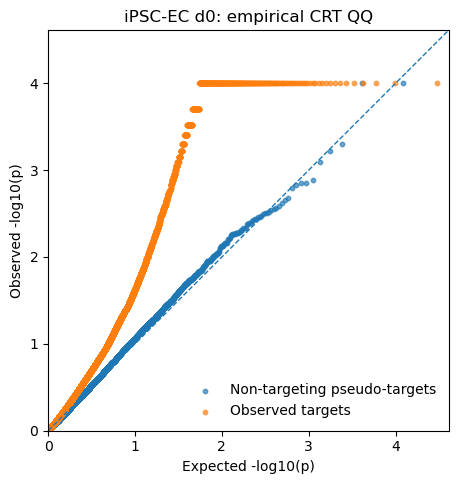

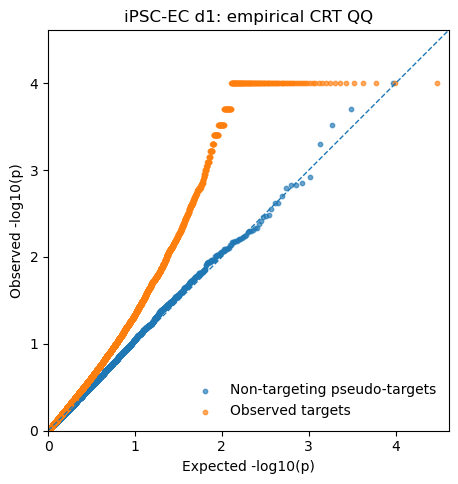

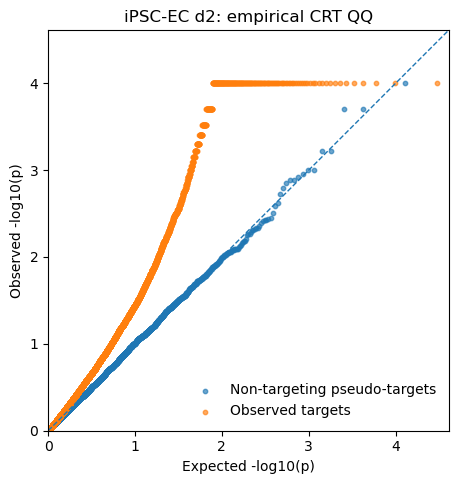

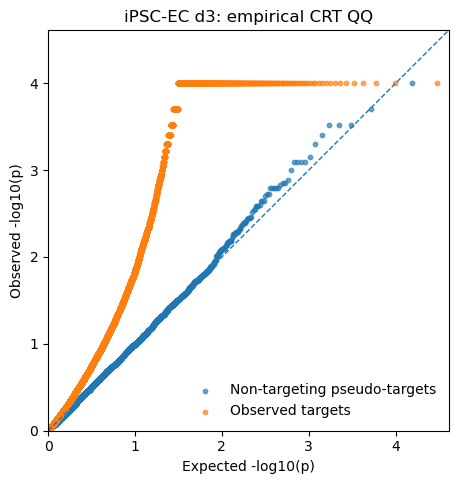

In [5]:
import matplotlib.pyplot as plt

plot_data = points.loc[
    (points['pvalue_type'] == 'empirical')
    & (points['series_type'].isin(['observed_target', 'ntc_pseudotarget']))
].copy()

for day, current in plot_data.groupby('day', sort=True):
    fig, ax = plt.subplots(figsize=(5.5, 5.2))
    for series_type, label in [
        ('ntc_pseudotarget', 'Non-targeting pseudo-targets'),
        ('observed_target', 'Observed targets'),
    ]:
        sub = current.loc[current['series_type'] == series_type]
        ax.scatter(sub['expected_neglog10_p'], sub['observed_neglog10_p'], s=10, alpha=0.65, label=label)
    lim = max(1.0, current['expected_neglog10_p'].max(), current['observed_neglog10_p'].max()) * 1.03
    ax.plot([0, lim], [0, lim], linestyle='--', linewidth=1)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('Expected -log10(p)')
    ax.set_ylabel('Observed -log10(p)')
    ax.set_title(f'iPSC-EC {day}: empirical CRT QQ')
    ax.legend(frameon=False)
    plt.show()

/tmp/ipykernel_64318/2500159175.py:59: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


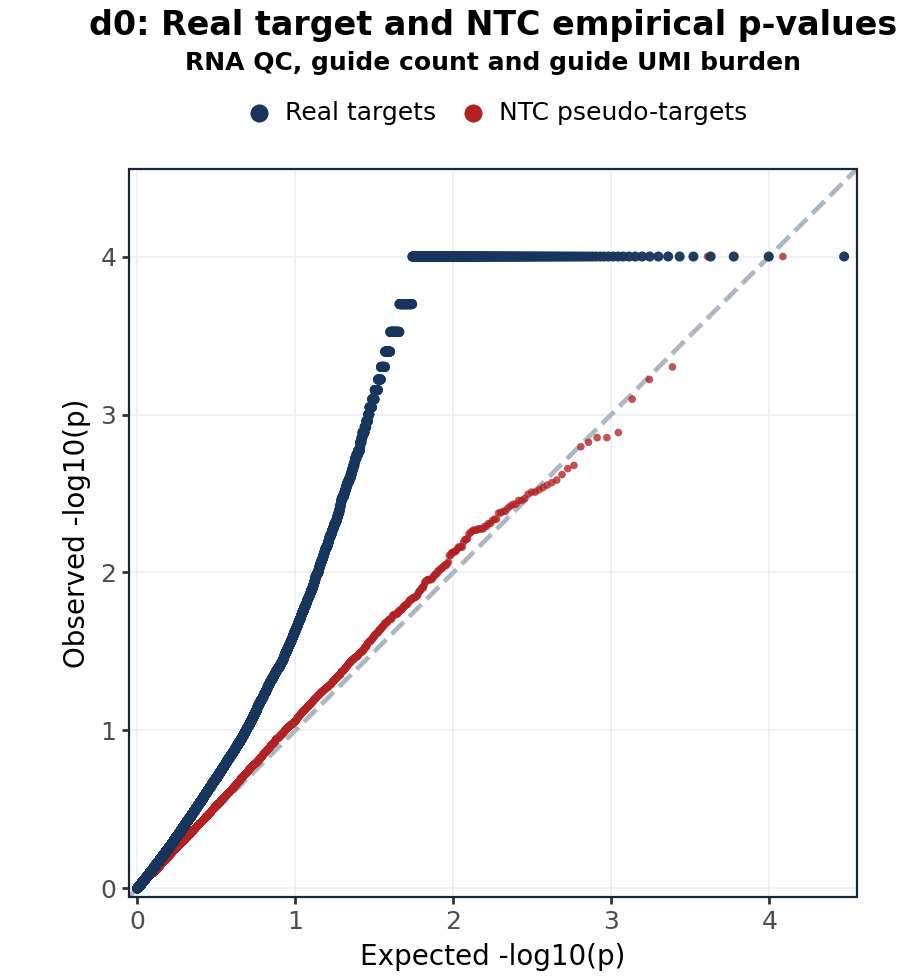

/tmp/ipykernel_64318/2500159175.py:59: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


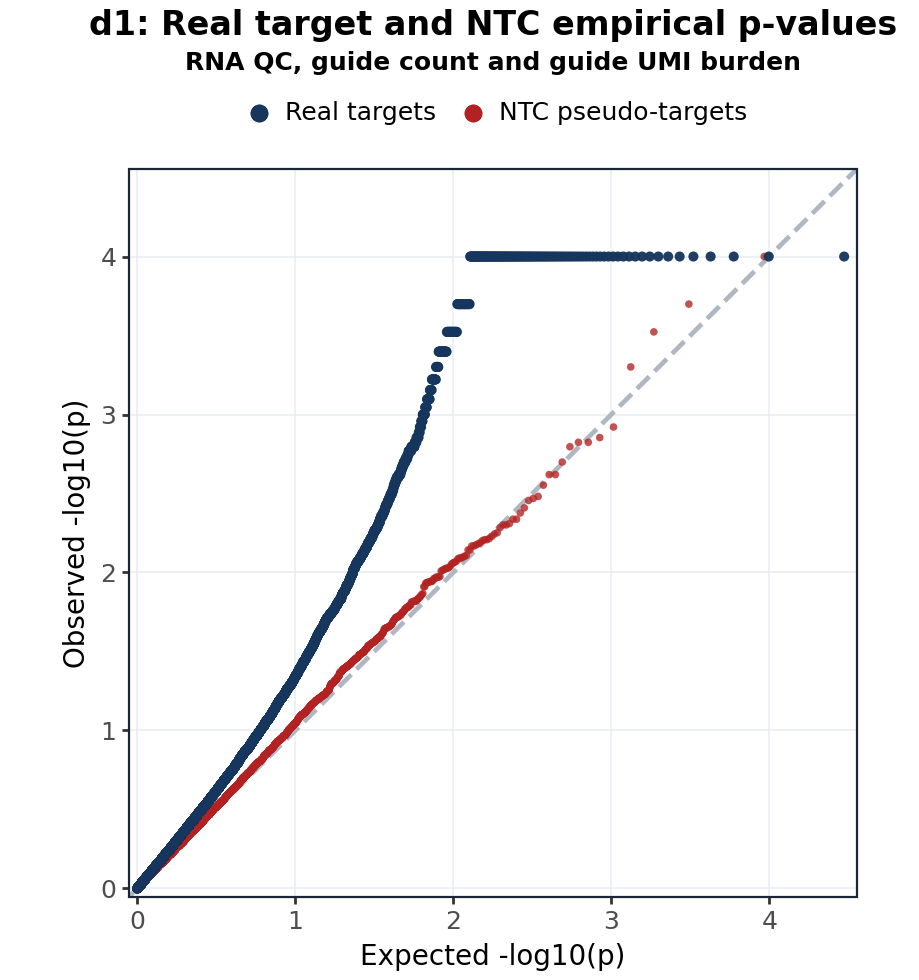

/tmp/ipykernel_64318/2500159175.py:59: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


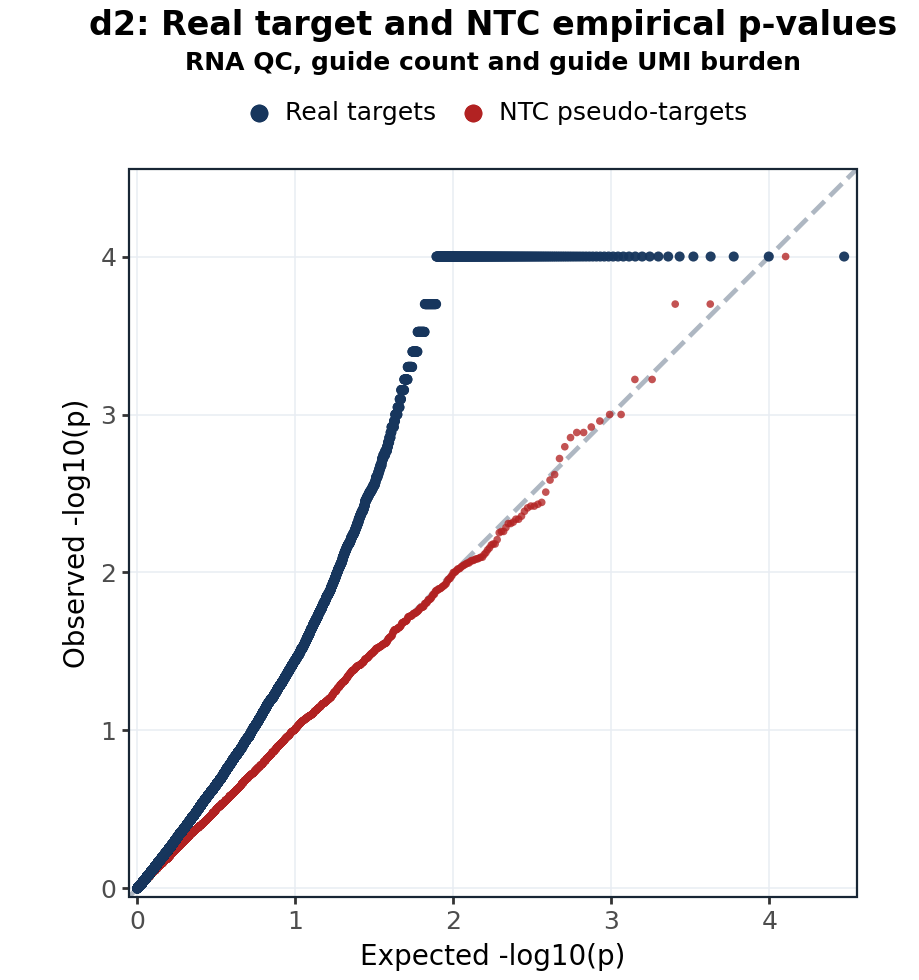

/tmp/ipykernel_64318/2500159175.py:59: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


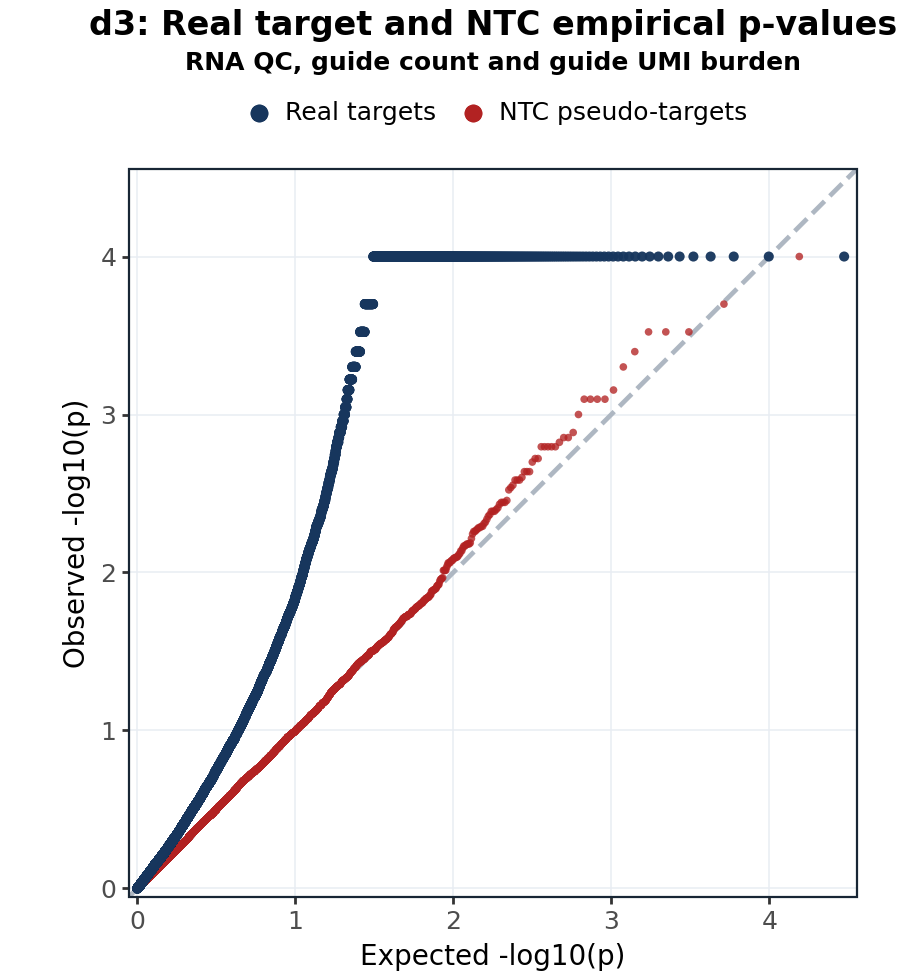

Saved files:

d0
  PDF: results/ipsc_ec_qq_exports/k_50.dt_0_2/illustrator_editable/d0_QQ_plotnine_legend_above.pdf
  SVG: results/ipsc_ec_qq_exports/k_50.dt_0_2/illustrator_editable/d0_QQ_plotnine_legend_above.svg
  EPS: results/ipsc_ec_qq_exports/k_50.dt_0_2/illustrator_editable/d0_QQ_plotnine_legend_above.eps
  PNG: results/ipsc_ec_qq_exports/k_50.dt_0_2/illustrator_editable/d0_QQ_plotnine_legend_above.png

d1
  PDF: results/ipsc_ec_qq_exports/k_50.dt_0_2/illustrator_editable/d1_QQ_plotnine_legend_above.pdf
  SVG: results/ipsc_ec_qq_exports/k_50.dt_0_2/illustrator_editable/d1_QQ_plotnine_legend_above.svg
  EPS: results/ipsc_ec_qq_exports/k_50.dt_0_2/illustrator_editable/d1_QQ_plotnine_legend_above.eps
  PNG: results/ipsc_ec_qq_exports/k_50.dt_0_2/illustrator_editable/d1_QQ_plotnine_legend_above.png

d2
  PDF: results/ipsc_ec_qq_exports/k_50.dt_0_2/illustrator_editable/d2_QQ_plotnine_legend_above.pdf
  SVG: results/ipsc_ec_qq_exports/k_50.dt_0_2/illustrator_editable/d2_QQ_plotnine_le

In [8]:
from pathlib import Path
from IPython.display import display
from plotnine import theme, guides, guide_legend, element_blank, element_text
import matplotlib as mpl

# Keep text editable in Illustrator vector exports.
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"


def qq_legend_above_panel(p, *, width=4.6, height=4.9):
    """
    Override the old in-panel legend placement.
    Places legend above the panel so it does not cover QQ points.
    """
    return (
        p
        + guides(
            color=guide_legend(
                nrow=1,
                override_aes={"size": 3.6, "alpha": 1},
            )
        )
        + theme(
            figure_size=(width, height),

            # Key change: outside the plotting panel
            legend_position="top",
            legend_direction="horizontal",

            # Remove the boxed legend look
            legend_background=element_blank(),
            legend_key=element_blank(),
            legend_title=element_blank(),
            legend_text=element_text(size=9),

            # Give the title/subtitle/legend enough room
            plot_title=element_text(size=12, weight="bold", ha="center"),
            plot_subtitle=element_text(size=9, weight="bold", ha="center"),
        )
    )


def save_illustrator_formats(
    p,
    output_stem,
    *,
    width=4.6,
    height=4.9,
    dpi=300,
    formats=("pdf", "svg", "eps", "png"),
):
    output_stem = Path(output_stem)
    output_stem.parent.mkdir(parents=True, exist_ok=True)

    saved = {}
    for fmt in formats:
        out = output_stem.with_suffix(f".{fmt}")
        kwargs = dict(width=width, height=height, units="in", verbose=False)
        if fmt == "png":
            kwargs["dpi"] = dpi

        p.save(out, **kwargs)
        saved[fmt] = out

    return saved


qq_csv = Path("results/ipsc_ec_qq_exports/k_50.dt_0_2/all_days_QQ_points.csv")
illustrator_out_dir = qq_csv.parent / "illustrator_editable"

all_saved_files = {}

for d in ["d0", "d1", "d2", "d3"]:

    # Important: output_stem=None here, otherwise the old in-panel legend version
    # gets saved before we apply the legend override.
    p = plot_ipsc_ec_qq(
        qq_csv,
        day=d,
        pvalue_type="empirical",
        title=f"{d}: Real target and NTC empirical p-values",
        subtitle="RNA QC, guide count and guide UMI burden",
        output_stem=None,
    )

    p = qq_legend_above_panel(p, width=4.6, height=4.9)

    saved = save_illustrator_formats(
        p,
        illustrator_out_dir / f"{d}_QQ_plotnine_legend_above",
        width=4.6,
        height=4.9,
        formats=("pdf", "svg", "eps", "png"),
    )

    all_saved_files[d] = saved
    display(p)

print("Saved files:")
for day, files in all_saved_files.items():
    print(f"\n{day}")
    for fmt, path in files.items():
        print(f"  {fmt.upper()}: {path}")